<a href="https://colab.research.google.com/github/nahsiz/99_days_of_coding_MLOps_With_CPC/blob/main/phase-1/day_14/day_14.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Import Required Libraries

Text Box Title: Importing Required Libraries

Text Box Description: Import Pandas, NumPy, Matplotlib, and Seaborn for data analysis and visualization.

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

2. Load the Dataset

Text Box Title: Loading the FuelConsumption Dataset

Text Box Description: Load the CSV file into a Pandas DataFrame and strip any extra whitespace from column names so the long column names with spaces work correctly.

In [18]:
data = pd.read_csv('/content/FuelConsumption.csv')
data.columns = data.columns.str.strip()

print("Dataset Loaded Successfully!")

Dataset Loaded Successfully!



3. Display First 5 Rows

Text Box Title: Displaying the First 5 Rows

Text Box Description: Use the head() function to quickly verify the dataset was loaded correctly.

In [19]:
data.head()

,Year,MAKE,MODEL,VEHICLE CLASS,ENGINE SIZE,CYLINDERS,TRANSMISSION,FUEL,FUEL CONSUMPTION,COEMISSIONS
0,2000,ACURA,1.6EL,COMPACT,1.6,4,A4,X,10.5,216
1,2000,ACURA,1.6EL,COMPACT,1.6,4,M5,X,9.8,205
2,2000,ACURA,3.2TL,MID-SIZE,3.2,6,AS5,Z,13.7,265
3,2000,ACURA,3.5RL,MID-SIZE,3.5,6,A4,Z,15.0,301
4,2000,ACURA,INTEGRA,SUBCOMPACT,1.8,4,A4,X,11.4,230


4. Select Four Columns (Shared X-Axis)

Text Box Title: Selecting Four Columns for Correlation Analysis

Text Box Description: Select one shared x-axis column (ENGINE SIZE) and three y-axis columns (FUEL CONSUMPTION, COEMISSIONS, CYLINDERS). ENGINE SIZE will stay on the x-axis in all scatter plots so the three relationships can be compared against the same horizontal axis.

In [20]:
x_col = 'ENGINE SIZE'
y_col_1 = 'FUEL CONSUMPTION'
y_col_2 = 'COEMISSIONS'
y_col_3 = 'CYLINDERS'

selected_data = data[[x_col, y_col_1, y_col_2, y_col_3]]

selected_data.head()

,ENGINE SIZE,FUEL CONSUMPTION,COEMISSIONS,CYLINDERS
0,1.6,10.5,216,4
1,1.6,9.8,205,4
2,3.2,13.7,265,6
3,3.5,15.0,301,6
4,1.8,11.4,230,4


5. Calculate Pearson Correlation

Text Box Title: Calculating Correlation Between Four Columns

Text Box Description: Calculate the Pearson correlation coefficient three times — ENGINE SIZE vs FUEL CONSUMPTION, ENGINE SIZE vs COEMISSIONS, and ENGINE SIZE vs CYLINDERS. ENGINE SIZE remains the shared x-axis column in all three calculations.

In [21]:
correlation_1 = selected_data[x_col].corr(selected_data[y_col_1])
correlation_2 = selected_data[x_col].corr(selected_data[y_col_2])
correlation_3 = selected_data[x_col].corr(selected_data[y_col_3])

print("Correlation between", x_col, "and", y_col_1)
print("Pearson Correlation Coefficient:", round(correlation_1, 4))
print()
print("Correlation between", x_col, "and", y_col_2)
print("Pearson Correlation Coefficient:", round(correlation_2, 4))
print()
print("Correlation between", x_col, "and", y_col_3)
print("Pearson Correlation Coefficient:", round(correlation_3, 4))

Correlation between ENGINE SIZE and FUEL CONSUMPTION
Pearson Correlation Coefficient: 0.8582

Correlation between ENGINE SIZE and COEMISSIONS
Pearson Correlation Coefficient: 0.8497

Correlation between ENGINE SIZE and CYLINDERS
Pearson Correlation Coefficient: 0.8938


6. Correlation Heatmap (4×4)

Text Box Title: Visualizing Correlation Using a Heatmap

Text Box Description: Create a 4×4 heatmap to display the correlation coefficients between all four selected columns at a glance.

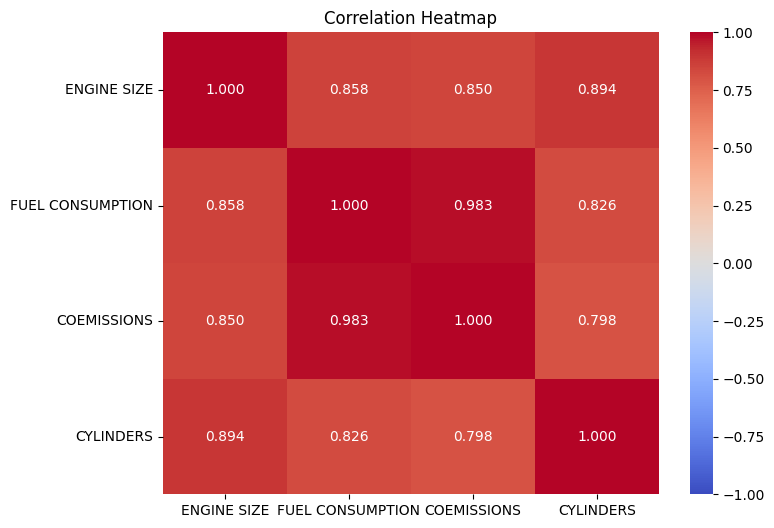

In [22]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    selected_data.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.3f',
    vmin=-1,
    vmax=1
)

plt.title('Correlation Heatmap')
plt.show()

7. Scatter Plot — Shared X with First Y

Text Box Title: Visualizing Engine Size vs Fuel Consumption

Text Box Description: Create a scatter plot with a regression line where ENGINE SIZE is on the x-axis and FUEL CONSUMPTION is on the y-axis. ENGINE SIZE stays on the x-axis because it is the shared axis for all three plots.

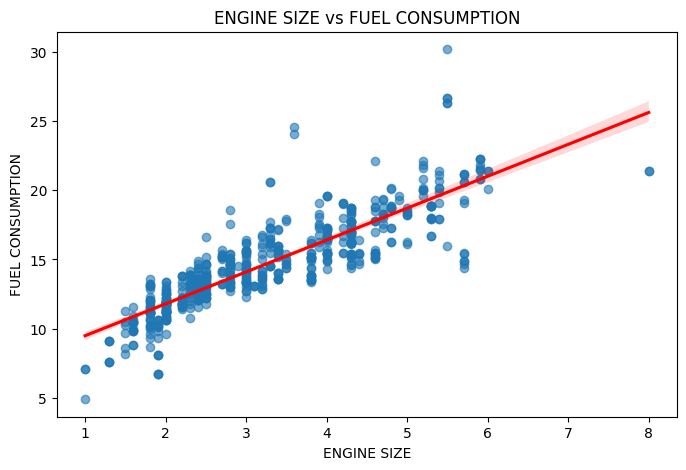

In [23]:
plt.figure(figsize=(8, 5))

sns.regplot(
    data=selected_data,
    x=x_col,
    y=y_col_1,
    scatter_kws={'alpha': 0.6},
    line_kws={'color': 'red'}
)

plt.title(f'{x_col} vs {y_col_1}')
plt.xlabel(x_col)
plt.ylabel(y_col_1)
plt.show()

8. Scatter Plot — Shared X with Second Y

Text Box Title: Visualizing Engine Size vs CO2 Emissions

Text Box Description: Create a scatter plot with a regression line where ENGINE SIZE is again on the x-axis, but COEMISSIONS is now on the y-axis. The x-axis stays identical to the previous plot so both relationships share the same horizontal axis.

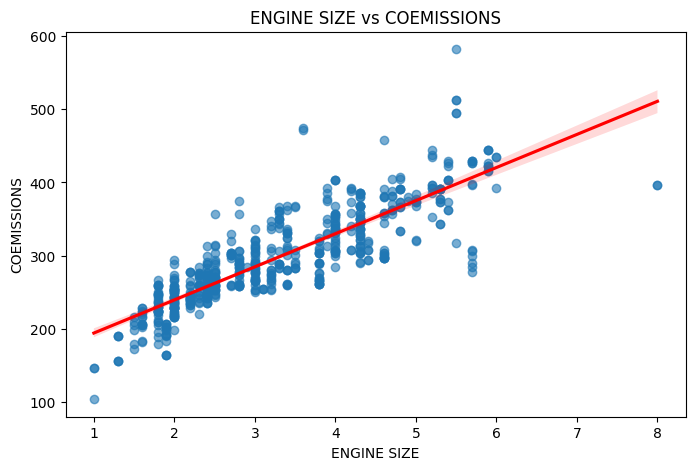

In [24]:
plt.figure(figsize=(8, 5))

sns.regplot(
    data=selected_data,
    x=x_col,
    y=y_col_2,
    scatter_kws={'alpha': 0.6},
    line_kws={'color': 'red'}
)

plt.title(f'{x_col} vs {y_col_2}')
plt.xlabel(x_col)
plt.ylabel(y_col_2)
plt.show()

9. Scatter Plot — Shared X with Third Y

Text Box Title: Visualizing Engine Size vs Cylinders

Text Box Description: Create a scatter plot with a regression line where ENGINE SIZE is again on the x-axis, but CYLINDERS is now on the y-axis. The x-axis stays identical so all three plots share the same horizontal axis.

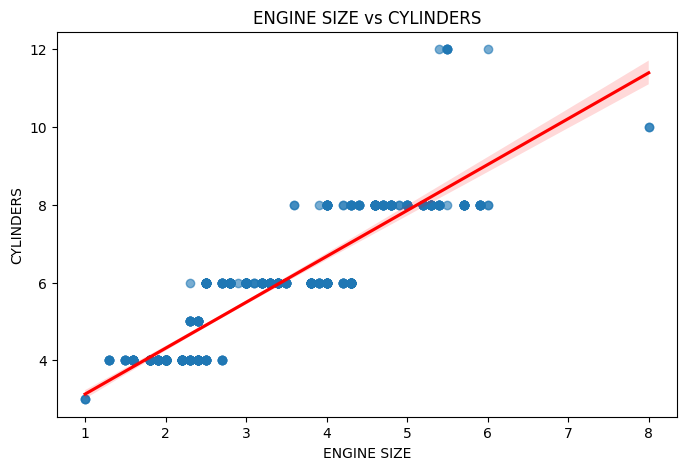

In [25]:
plt.figure(figsize=(8, 5))

sns.regplot(
    data=selected_data,
    x=x_col,
    y=y_col_3,
    scatter_kws={'alpha': 0.6},
    line_kws={'color': 'red'}
)

plt.title(f'{x_col} vs {y_col_3}')
plt.xlabel(x_col)
plt.ylabel(y_col_3)
plt.show()

10. Interpret the First Correlation Result

Text Box Title: Interpreting the First Correlation Coefficient

Text Box Description: Identify whether the relationship between ENGINE SIZE and FUEL CONSUMPTION is positive, negative, or has no linear correlation.

In [26]:
if correlation_1 > 0:
    print("Positive Correlation")
elif correlation_1 < 0:
    print("Negative Correlation")
else:
    print("No Linear Correlation")

print("Correlation Value:", round(correlation_1, 4))

Positive Correlation
Correlation Value: 0.8582


11. Interpret the Second Correlation Result

Text Box Title: Interpreting the Second Correlation Coefficient

Text Box Description: Identify whether the relationship between ENGINE SIZE and COEMISSIONS is positive, negative, or has no linear correlation.

In [27]:
if correlation_2 > 0:
    print("Positive Correlation")
elif correlation_2 < 0:
    print("Negative Correlation")
else:
    print("No Linear Correlation")

print("Correlation Value:", round(correlation_2, 4))

Positive Correlation
Correlation Value: 0.8497


12. Interpret the Third Correlation Result

Text Box Title: Interpreting the Third Correlation Coefficient

Text Box Description: Identify whether the relationship between ENGINE SIZE and CYLINDERS is positive, negative, or has no linear correlation.

In [28]:
if correlation_3 > 0:
    print("Positive Correlation")
elif correlation_3 < 0:
    print("Negative Correlation")
else:
    print("No Linear Correlation")

print("Correlation Value:", round(correlation_3, 4))

Positive Correlation
Correlation Value: 0.8938


13. Display Final Correlation Result

Text Box Title: Final Correlation Analysis Result

Text Box Description: Display the shared x-axis column name and all three y-axis column names along with their calculated Pearson correlation coefficients.

In [29]:
print("Final Correlation Analysis")
print("--------------------------")

print("Shared X-Axis Column :", x_col)
print("First Y-Axis Column  :", y_col_1)
print("Pearson Correlation  :", round(correlation_1, 4))
print()

print("Shared X-Axis Column :", x_col)
print("Second Y-Axis Column :", y_col_2)
print("Pearson Correlation  :", round(correlation_2, 4))
print()

print("Shared X-Axis Column :", x_col)
print("Third Y-Axis Column  :", y_col_3)
print("Pearson Correlation  :", round(correlation_3, 4))

Final Correlation Analysis
--------------------------
Shared X-Axis Column : ENGINE SIZE
First Y-Axis Column  : FUEL CONSUMPTION
Pearson Correlation  : 0.8582

Shared X-Axis Column : ENGINE SIZE
Second Y-Axis Column : COEMISSIONS
Pearson Correlation  : 0.8497

Shared X-Axis Column : ENGINE SIZE
Third Y-Axis Column  : CYLINDERS
Pearson Correlation  : 0.8938
